### Lecture Notes: More Examples on Hypothesis Testing & Assessing Models

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html)

**Recommended Readings:**
- [Assessing a Model](https://www.inferentialthinking.com/chapters/11/1/Assessing_a_Model.html)
- [Decisions and P-value](https://www.inferentialthinking.com/chapters/11/3/Decisions_and_Uncertainty.html)
- [A/B Testing](https://www.inferentialthinking.com/chapters/12/1/AB_Testing.html)
- [Testing two proportions](https://www.inferentialthinking.com/chapters/12/2/Causality.html)

In [389]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
students = Table().read_table('student_data.csv')


### Hypothesis Testing Based on Simulations

1. State the null and alternative hypothesis
2. Pick a test statistic
3. Simulate the sampling distribution of the test statistic, under the null hypothesis (model)
4. Draw conclusion based on the results of the random sampling distribution simulation and empirical (real world data) distributions.

### Test Statistic

Test statistic is typically used to make decision on null vs alternative hypothese.

We have learned difference in means, absolute difference in means and total variation distance (TVD).

Difference in means: for 2 numerical groups, compare whether one group performs better or worse that the other in alternative hypothesis.

Absolution difference in means: for 2 numerical groups, compare whether the groups are difference in alternative hypothesis.

Total variation distance (TVD): for multiple categories with different proportions (non numerical data), compare whether the distributions are different.


### Useful `datascience` library functions

`sample_proportions()` returns an array.

`samples()` returns a table.

We may start with simulating one value of the test statistic and then use a `for`-loop to simulate multiple values of the test statistic.

### Use Total Variation Distance (TVD) as Test Statistic and Calculate the Real World Observed TVD Value

1. compute the differences of the fair die and the loaded die
2. take the the absolute value of each differences
3. add up all the differences and divide the total by 2

### A/B Testing

In A/B testing, we ask whether the two samples are likely from the same population.

Under the null model, the sampling distribution of the test statistic was generated using a technique called "label shuffling" or "Permutation Shuffling" (random assignment)

In [390]:
students = Table().read_table('student_data.csv')
students

SEX,COLOR,ZIP,MATH,PAPER,CAR,SHOE,AGE,HEIGHT,PETS,SOCIAL
Female,Blue,95403,3,2,2018,6.5,20,61,0,Yes
Female,Other,95401,2,5,2007,6.5,26,61,1,No
Female,Green,95492,1,3,1994,5.5,22,62,4,Yes
Female,Black,95472,3,3,nan,8,19,62,2,Yes
Female,Purple,95409,2,2,1990,7,19,63,3,Yes
Female,Orange,95407,4,3,2016,8.5,37,63,2,Yes
Female,Blue,95401,5,4,2003,8,17,63,5,Yes
Female,Blue,94928,3,3,2012,7.5,18,63,6,Yes
Female,Purple,95403,4,5,nan,8.5,36,63,0,No
Female,Red,95404,2,2,2011,7.5,20,64,7,Yes


In [391]:
students.group('COLOR').show()

COLOR,count
Black,6
Blue,26
Green,12
Grey,1
Orange,5
Other,3
Pink,1
Purple,9
Red,7
White,1


### Social Media and Average Age

Based on the student data in `student_data.csv`, suppose we want to test the hypothesis that students who do not use social media tend to be older in terms of average age.

**Null hypothesis**: people who don't use social networks have the same mean of age as the rest of the students.

**Alternative hypothesis**: people who don't use social networks have a higher mean of age as the rest of the students.

**Test statistic**: the difference between the two sample means (the average age)

Performing A/B Testing

In [392]:
# create a table to contain a label and a variable for A/B testing
#   the labels will be shufflied and randomly associated to the variable column 
social_and_age = students.select("SOCIAL", "AGE")
social_and_age

SOCIAL,AGE
Yes,20
No,26
Yes,22
Yes,19
Yes,19
Yes,37
Yes,17
Yes,18
No,36
Yes,20


In [393]:
# use tbl.group() function to count the A and B categories
social_and_age.group("SOCIAL")

SOCIAL,count
No,20
Yes,54


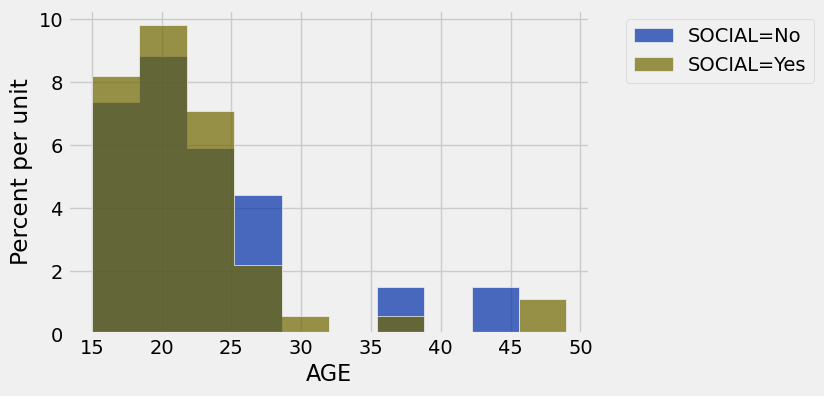

In [394]:
# visualize the distribution
social_and_age.hist("AGE", group="SOCIAL")

In [395]:
# check the average age 
means_table = social_and_age.group("SOCIAL", np.average)
means_table

SOCIAL,AGE average
No,22.95
Yes,22.1296


In [396]:
# compute the average based on the real data
means = means_table.column(1)
observed_difference = means.item(0) - means.item(1)
observed_difference

0.8203703703703695

In [397]:
# to help simulating the sampling distribution of the test statistic,
#   we create a function to compute an average based on 
#   the table, label and variable in the parameter list
def difference_of_means(table, label, variable):
    subtable = table.select(label, variable)
    means_table = subtable.group(label, np.average)
    means = means_table.column(1)
    return means.item(0) - means.item(1)

observed_diff = difference_of_means(students, "SOCIAL", "AGE")
observed_diff

0.8203703703703695

In [398]:
# to do A/B testing, we shuffle the labels and randomly re-associated them to variable column
# random assignment
shuffled_labels = social_and_age.sample(with_replacement = False).column(0)
original_and_shuffled = social_and_age.with_columns("Shuffled Label", shuffled_labels)
original_and_shuffled

SOCIAL,AGE,Shuffled Label
Yes,20,No
No,26,Yes
Yes,22,Yes
Yes,19,Yes
Yes,19,Yes
Yes,37,Yes
Yes,17,Yes
Yes,18,Yes
No,36,No
Yes,20,Yes


In [399]:
# check the average after label shuffling
shuffled_only = original_and_shuffled.select("AGE", "Shuffled Label")
shuffled_group_mean = shuffled_only.group('Shuffled Label', np.average)
shuffled_group_mean

Shuffled Label,AGE average
No,22.8
Yes,22.1852


In [400]:
# call the function to compute the average for the shufflied label
#   this is the average based on the shufflied data
difference_of_means(original_and_shuffled, "Shuffled Label", "AGE")

0.6148148148148138

In [401]:
# call the function to compute the average for the original label
#   this is the average based on the real data
difference_of_means(original_and_shuffled, "SOCIAL", "AGE")

0.8203703703703695

In [402]:
# function to simulate one the sampling distribution of the test statistic
def one_simulated_difference_of_means(table, label, variable):
    # sample the entire table and create shufflied labels
    shuffled_labels = table.sample(with_replacement=False).column(label)
    shuffled_table = table.select(variable).with_column(
        "Shuffled Label", shuffled_labels)
    # call a function to compute a simulated test statistic 
    return difference_of_means(shuffled_table, "Shuffled Label", variable)

In [403]:
one_simulated_difference_of_means(social_and_age, "SOCIAL", "AGE")

3.4925925925925903

In [404]:
# repeat the simulation many times
simulated_differences = make_array()

repeats = 5000
for i in np.arange(repeats):
    new_difference = one_simulated_difference_of_means(social_and_age, "SOCIAL", "AGE")
    simulated_differences = np.append(simulated_differences, new_difference)

Observed Difference: 0.8203703703703695


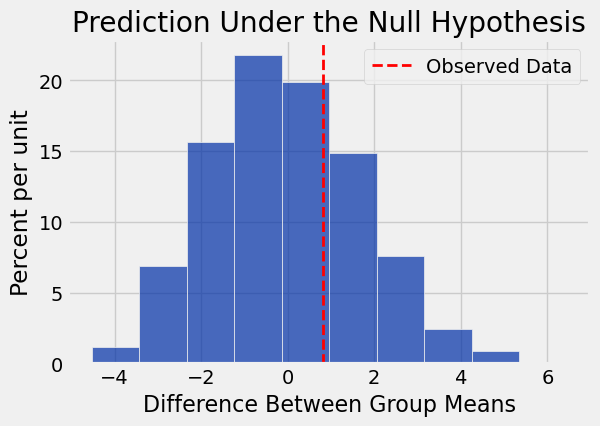

In [405]:
Table().with_column('Difference Between Group Means', simulated_differences).hist()
print('Observed Difference:', observed_difference)
plots.title('Prediction Under the Null Hypothesis');
#plots.scatter(observed_difference, 0.005, color='red', s=100)
plots.axvline(observed_difference, color='red', linestyle='--', linewidth=2, label='Observed Data')
plots.legend()

In [406]:
# p-value >= 0.05 support null hypothesis that is the assumption of random sampling
# p-value < 0.05, the data provides strong evidence against the null hypothesis
p_value = np.count_nonzero(simulated_differences >= observed_difference) / repeats
p_value

0.31159999999999999

So the data is consistent with the null. There is no evidence to show people who don't use social network are older.

### Lithium Prevent Cocaine Users from Relapsing (Categorical Data)

The following data records an experiment on whether Lithium was effective in preventing cocaine users from relapsing. In the column labeled "Result", 1 represents relapse (returning to cocaine use), and 0 presents no relapse.

**Null hypothesis**: (control group) Lithium was not effective in preventing cocaine users from relapsing.

**Alternative hypothesis**: (treatment group) Lithium was effective in preventing cocaine users from relapsing.

**Test statistic**: the absolute value of the difference in the success rate between the two groups (small absolute values support the null hypothesis, otherwise support the alternative hypothesis)

Performing A/B Testing (label shuffling) - random assignment

In [407]:
coke = Table().read_table('cocaine_lithium.csv')
coke.show(3)

Group,Result
Lithium,1
Lithium,1
Lithium,1


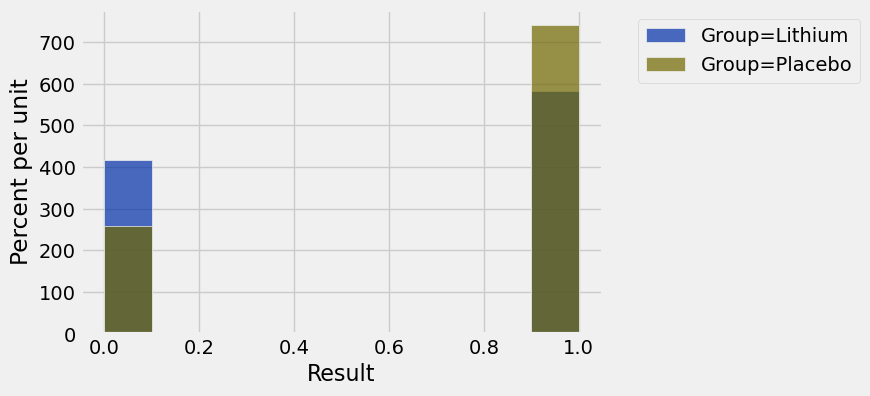

In [408]:
# the table doesn't really have numerical values
#   the 1s and 0s represent boolean values
# so histogram doesn't make much sense
# remember histogram is used to visual the distribution of continuous numerical data
coke.hist(group="Group")

In [409]:
# let's summerize the data using a pivot table
coke.pivot('Result', 'Group')

Group,0,1
Lithium,10,14
Placebo,7,20


In [410]:
# average success rates
coke_avg = coke.group('Group', np.average)
coke_avg

Group,Result average
Lithium,0.583333
Placebo,0.740741


In [411]:
# how far/close of the success rate between the control and treatment groups
observed_distance = abs(coke_avg.column('Result average').item(0) - coke_avg.column('Result average').item(1))
observed_distance

0.15740740740740733

In [412]:
# create a function to computer the distance between the control and treatment groups
def distance(table, group_label):
    proportions = table.group(group_label, np.average).column(1)
    #print(proportions)
    return abs(proportions.item(1) - proportions.item(0))

distance(coke, 'Group')

0.15740740740740733

In [413]:
# function to simulate one the sampling distribution of the test statistic
def one_simulated_distance(table, label, variable):
    # sample the entire table and create shufflied labels
    shuffled_labels = table.sample(with_replacement=False).column(label)
    shuffled_table = table.select(variable).with_column(
        "Shuffled Label", shuffled_labels)
    # call a function to compute a simulated test statistic 
    return distance(shuffled_table, "Shuffled Label")

In [414]:
one_simulated_distance(coke, "Group", "Result")

0.07870370370370372

Observed Difference: 0.15740740740740733


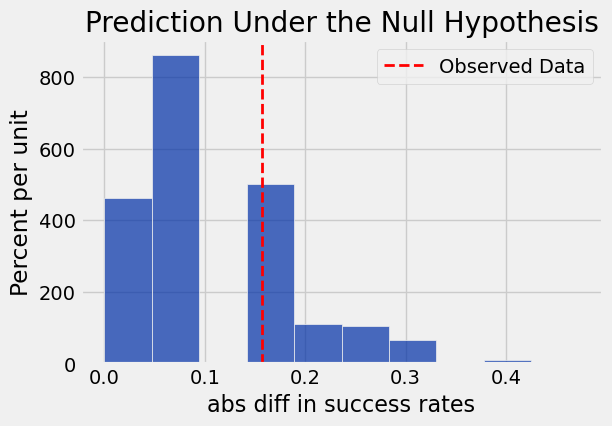

In [415]:
# repeat the simulation many times
simulated_distances = make_array()

repeats = 5000
for i in np.arange(repeats):
    new_distance = one_simulated_distance(coke, "Group", "Result")
    simulated_distances = np.append(simulated_distances, new_distance)

Table().with_column('abs diff in success rates', simulated_distances).hist()

print('Observed Difference:', observed_distance)
plots.title('Prediction Under the Null Hypothesis');
#plots.scatter(observed_difference, 0.005, color='red', s=100)
plots.axvline(observed_distance, color='red', linestyle='--', linewidth=2, label='Observed Data')
plots.legend()

#### Would you recommend this treament to anyone?

#### What do you think the p-value limit should be?

#### let's look at the p-value

In [416]:
# let's look at the p-value
# p-value >= 0.05 support null hypothesis that is the assumption of random sampling
# p-value < 0.05, the data provides strong evidence against the null hypothesis
np.count_nonzero(simulated_distances >= observed_distance) / repeats

0.37559999999999999

### Social Media and Assignments submissions

**Null hypothesis**: students use social media submit similar numbers of assignments on average as the students don't use social media

**Alternative hypothesis**: students use social media submit less assignments on average than the students don't use social media

**Test statistic**: the difference between the two sample means (the average number of assignments submitted)


In [417]:
students.show(3)

SEX,COLOR,ZIP,MATH,PAPER,CAR,SHOE,AGE,HEIGHT,PETS,SOCIAL
Female,Blue,95403,3,2,2018,6.5,20,61,0,Yes
Female,Other,95401,2,5,2007,6.5,26,61,1,No
Female,Green,95492,1,3,1994,5.5,22,62,4,Yes


In [418]:
hw = students.column('MATH') + students.column('PAPER')
social_and_hw = Table().with_columns('SOCIAL', students.column('SOCIAL'), 'HOMEWORK', hw)
social_and_hw.show(3)

SOCIAL,HOMEWORK
Yes,5
No,7
Yes,4


In [419]:
social_and_hw.group('SOCIAL')

SOCIAL,count
No,20
Yes,54


In [420]:
social_and_hw.pivot('HOMEWORK', 'SOCIAL')

SOCIAL,2,3,4,5,6,7,8,9
No,0,1,2,5,4,4,3,1
Yes,1,2,9,12,19,5,5,1


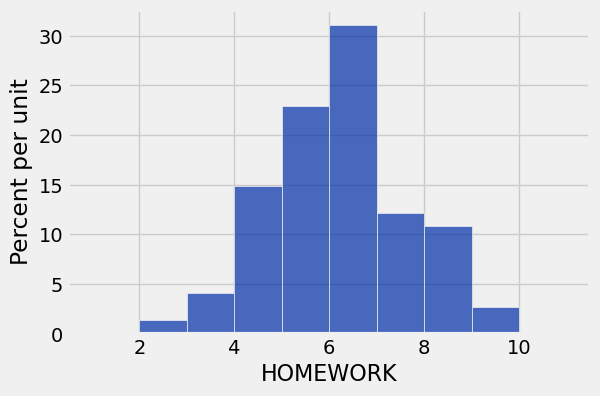

In [421]:
social_and_hw.hist('HOMEWORK', bins=np.arange(1, 12, 1))

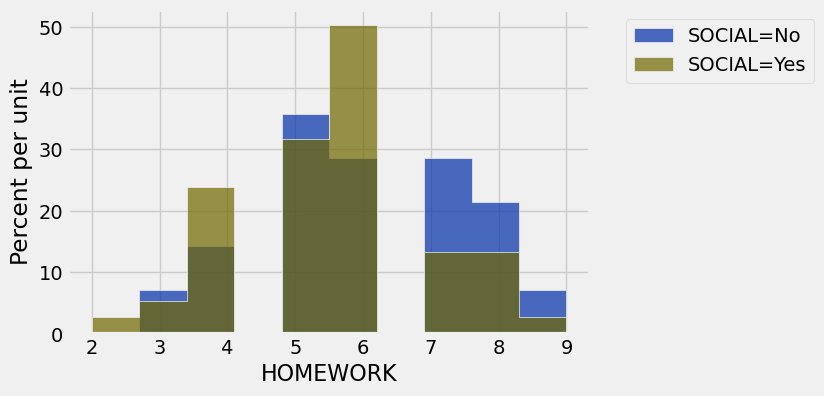

In [422]:
hw_and_social.hist("HOMEWORK", group="SOCIAL")

In [423]:
means_table = social_and_hw.group("SOCIAL", np.average)
means_table

SOCIAL,HOMEWORK average
No,6.05
Yes,5.59259


In [424]:
means = means_table.column(1)
observed_difference = means.item(0) - means.item(1)
observed_difference

0.45740740740740726

In [425]:
observed_diff = difference_of_means(social_and_hw, "SOCIAL", "HOMEWORK")
observed_diff

0.45740740740740726

In [426]:
shuffled_labels = social_and_hw.sample(with_replacement = False).column(0)
original_and_shuffled = social_and_hw.with_columns("Shuffled Label", shuffled_labels)
original_and_shuffled

SOCIAL,HOMEWORK,Shuffled Label
Yes,5,Yes
No,7,Yes
Yes,4,Yes
Yes,6,No
Yes,4,Yes
Yes,7,Yes
Yes,9,Yes
Yes,6,Yes
No,9,No
Yes,4,Yes


In [427]:
shuffled_only = original_and_shuffled.select("HOMEWORK", "Shuffled Label")
shuffled_group_mean = shuffled_only.group('Shuffled Label', np.average)
shuffled_group_mean

Shuffled Label,HOMEWORK average
No,6.35
Yes,5.48148


In [428]:
difference_of_means(original_and_shuffled, "Shuffled Label", "HOMEWORK")

0.8685185185185178

In [429]:
difference_of_means(original_and_shuffled, "SOCIAL", "HOMEWORK")

0.45740740740740726

In [430]:
one_simulated_difference_of_means(social_and_hw, "SOCIAL", "HOMEWORK")

0.45740740740740726

In [431]:
simulated_differences = make_array()

repeats = 5000
for i in np.arange(repeats):
    new_difference = one_simulated_difference_of_means(social_and_hw, "SOCIAL", "HOMEWORK")
    simulated_differences = np.append(simulated_differences, new_difference)

Observed Difference: 0.45740740740740726


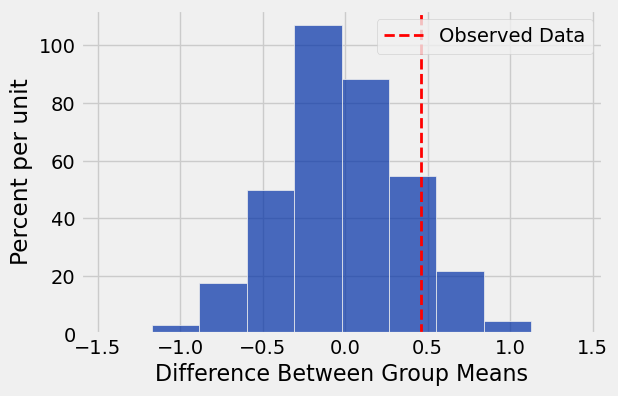

In [432]:
Table().with_column('Difference Between Group Means', simulated_differences).hist()
print('Observed Difference:', observed_difference)
plots.axvline(observed_difference, color='red', linestyle='--', linewidth=2, label='Observed Data')
plots.legend()

In [433]:
# p-value >= 0.05 support null hypothesis that is the assumption of random sampling
# p-value < 0.05, the data provides strong evidence against the null hypothesis
p_value = np.count_nonzero(simulated_differences <= observed_difference) / repeats
p_value

0.8982